In [1]:
import numpy as np
import glob
from tqdm import tqdm
import os
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from PIL import Image
import shutil

In [2]:
# intermediate_file_path = '../datasetGAN/intermediate_data/tee_00'

In [18]:
coco = COCO('instances_Train.json')
img_dir = '/data/deep_tee/cvat_data'
image_id = 100

loading annotations into memory...
Done (t=0.31s)
creating index...
index created!


In [19]:
img = coco.imgs[image_id]

In [23]:
len(coco.imgs)

37808

In [30]:
coco.imgs[300]

{'id': 300,
 'width': 200,
 'height': 150,
 'file_name': 'frame_000299.PNG',
 'license': 0,
 'flickr_url': '',
 'coco_url': '',
 'date_captured': 0}

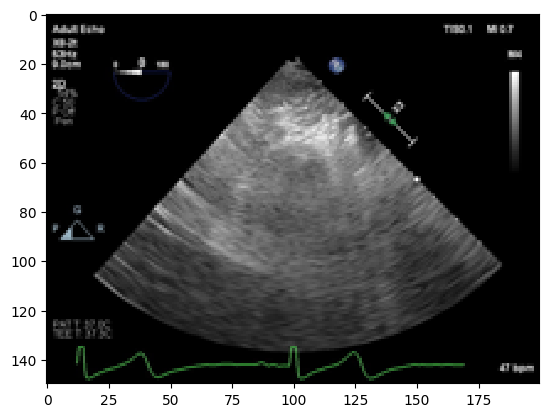

In [20]:
image = np.array(Image.open(os.path.join(img_dir, img['file_name'])))
plt.imshow(image, interpolation='nearest')
plt.show()

0

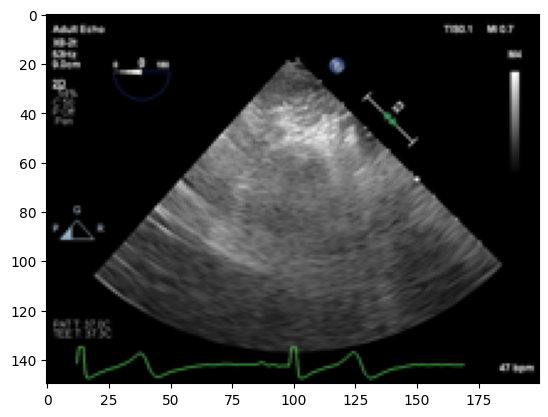

In [21]:
plt.imshow(image)
cat_ids = coco.getCatIds()
anns_ids = coco.getAnnIds(imgIds=img['id'], catIds=cat_ids, iscrowd=None)
anns = coco.loadAnns(anns_ids)
coco.showAnns(anns)

In [7]:
coco = COCO(f'{intermediate_file_path}/instances_default.json')
img_dir = intermediate_file_path
save_dir = f'{intermediate_file_path}/masks'
cat_ids = coco.getCatIds()

id_dict = [0,15,3,1,2,4,9,10,11,12,5,6,7,8,13,14] #for determining category priority

for image_id in tqdm(range(1,len(coco.imgs)+1)):
    img = coco.imgs[image_id]
    # basefile = os.path.splitext(img['file_name'])[0]
    basenumber = os.path.splitext(img['file_name'])[0][6:]
    # image = np.array(Image.open(os.path.join(img_dir, img['file_name'])))
    anns_ids = coco.getAnnIds(imgIds=img['id'], catIds=cat_ids, iscrowd=None)
    anns = coco.loadAnns(anns_ids)
    anns_img = np.zeros((img['height'],img['width']))
    for ann in anns:
        anns_img = np.maximum(anns_img,coco.annToMask(ann)*id_dict[ann['category_id']])
    # if np.sum(anns_img): #if not empty
    with open('{}/image_mask{}.npy'.format(save_dir,basenumber), 'wb') as f:
        np.save(f, np.expand_dims(anns_img, axis=0))
    plt.imsave('{}/saved_image_mask{}.png'.format(save_dir,basenumber), anns_img)
    shutil.copy2('{}/{}'.format(img_dir,img['file_name']), '{}/{}'.format(save_dir,img['file_name']))
        

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


100%|██████████| 100/100 [00:00<00:00, 683.00it/s]


In [25]:
# #file renamer

# img_dir = 'masks/train'
# save_dir = 'masks_ordered/train'
# filelist = sorted(glob.glob('masks/train/*.jpg'))

# for index,file in tqdm(enumerate(filelist)):
#     basenumber = os.path.splitext(os.path.basename(file))[0][6:]
#     shutil.copy2('{}/image_{}.jpg'.format(img_dir,basenumber), '{}/image_{}.jpg'.format(save_dir,index))
#     shutil.copy2('{}/image_mask{}.npy'.format(img_dir,basenumber), '{}/image_mask{}.npy'.format(save_dir,index))
